In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
os.chdir('../../')
PROJECT_ROOT = os.getcwd()
from codes.calculate_ae_charged import vector_to_param_changes
from codes.gradients import ensure_param_file
from matplotlib.lines import Line2D

np.set_printoptions(threshold=np.inf)

In [2]:
def generate_parameter_info(param_changes, variation=0.30, kernel_abs=0.03, near_one_width=0.20, positivity_eps=1e-12, fallback_zero_abs=0.20, fixed_components=None):
    """
    Flatten nested parameter dict into (names, bounds, vector, structure) with physics-aware bounds.

    Rules encoded:
      - dkernel, qkernel: tight symmetric bounds around 0: [-kernel_abs, +kernel_abs].
      - gam: strictly positive (lower bound clipped to >0).
      - lgam: each entry near 1.0: [1 - near_one_width, 1 + near_one_width], clipped >0. First component is always fixed to 1.0 (s orbital).
      - kpair (scalar or list; key == 'kpair' or startswith 'kpair'): near 1.0: [1 - near_one_width, 1 + near_one_width].
      - Everything else: ±variation box or one-sided box; if nominal==0 use ±fallback_zero_abs.

    Args:
      param_changes: nested dict {elem: {key: val or list[val,...]}}
      variation: fractional ± range around nominal (e.g., 0.20 for ±20%)
      kernel_abs: half-width for near-zero kernel bounds (absolute)
      near_one_width: half-width for parameters that should stay near 1.0 (lgam, kpair)
      positivity_eps: tiny positive floor for >0 constraints
      fallback_zero_abs: half-width if nominal value is 0 and % bounds would collapse
    """
    if fixed_components is None:
        fixed_components = set()  # set of (elem, key, idx) to fix like {("Na", "levels", 1), ("Na", "slater", 1)}

    def _percent_box(val, variation=variation):
        """Symmetric ±variation around nominal; special-case val==0."""
        if val == 0:
            return [-fallback_zero_abs, +fallback_zero_abs]
        lo = min(val * (1 - variation), val * (1 + variation))
        hi = max(val * (1 - variation), val * (1 + variation))
        return [lo, hi]

    def _clip_pos(lo):
        """Clip lower bound to be strictly positive."""
        return max(lo, positivity_eps)

    def _near_one_box():
        return [max(positivity_eps, 1.0 - near_one_width), 1.0 + near_one_width]

    def _kernel_zero_box():
        return [-abs(kernel_abs), +abs(kernel_abs)]

    def _make_bound(elem, key, val, idx=None):
        """
        Build a [lo,hi] bound for a single scalar 'val' given rules for (elem,key[,idx]).
        """
        # 1) Special keys first
        # kernels near zero
        if key in ("dkernel") and elem == 'Na':
            lo, hi = _kernel_zero_box()

        # kpair (scalar or list) near 1.0
        elif key == "Na-O" or key == "Na-H" or key == "Cl-H" or key == "Cl-O" or key == "H-H" or key == "O-O" or key == "O-H":
            lo, hi = _near_one_box()
            lo = _clip_pos(lo)

        # gam: positive, use % (or one-sided if provided) then clip >0
        elif key == "gam":
            box = _percent_box(val)
            lo, hi = box[0], box[1]
            lo = _clip_pos(lo)

        # default: % box or one-sided box if specified
        else:
            lo, hi = (_percent_box(val))

        # Ensure valid interval (hi>lo). If degenerate/invalid, nudge.
        if not (hi > lo):
            mid = 0.5 * (lo + hi)
            eps = max(1e-9, abs(mid) * 1e-12)
            lo, hi = mid - eps, mid + eps

        return [lo, hi]

    names = []
    bounds = []
    vector = []
    structure = {}

    for elem, params in param_changes.items():
        structure[elem] = {}
        for key, value in params.items():
            if isinstance(value, list):
                structure[elem][key] = []
                for i, val in enumerate(value):
                    if key == 'lgam' and i == 0: # fix first lgam to 1.0 -> s orbital
                        structure[elem][key].append('Fixing to 1.0')
                        continue
                    if (elem, key, i) in fixed_components:
                        #structure[elem][key].append(f'Fixed component {elem}_{key}_{i}')
                        structure[elem][key].append(("__fixed__", val))
                        continue
                    par_name = f"{elem}_{key}_{i}"
                    bnd = _make_bound(elem, key, val, idx=i)
                    names.append(par_name)
                    bounds.append(bnd)
                    vector.append(val)
                    structure[elem][key].append(par_name)
            else:
                par_name = f"{elem}_{key}"
                bnd = _make_bound(elem, key, value, idx=None)
                names.append(par_name)
                bounds.append(bnd)
                vector.append(value)
                structure[elem][key] = par_name

    return names, bounds, vector, structure

param_changes = {
    "kpair": {
        "O-O": 1.0,
        "O-H": 1.0,
    },
    "H": {
        "zeff": 1.1053880000000000,
        "arep": 2.2137169999999999,
    },
    "O": {
        "zeff": 5.7844150000000001,
        "arep": 2.1657120000000001,
    },
}

names, bounds, default_gfn2_vector, structure = generate_parameter_info(param_changes, fixed_components=None)
print("Parameter names:")
print(names)
print("Bounds:")
print(bounds)
print(f"Number of included parameters {len(names)}")

Parameter names:
['kpair_O-O', 'kpair_O-H', 'H_zeff', 'H_arep', 'O_zeff', 'O_arep']
Bounds:
[[0.8, 1.2], [0.8, 1.2], [0.7737716, 1.4370044000000002], [1.5496018999999999, 2.8778321], [4.0490905, 7.5197395], [1.5159984, 2.8154256]]
Number of included parameters 6


In [ ]:
results_path = os.path.join(PROJECT_ROOT, 'optimization/T1_partial_charge_schemes/hpc_runs/nsga_t1_ef_water_215904_20260720_101414/nsga3_results_t1_EF_param_reg_nsga_t1_ef_water_215904_20260720_101414.npz') # with O-O scan

with np.load(results_path) as data:
    X_pareto = data['X_pareto']
    F_pareto = data['F_pareto']

print("X_pareto shape:", X_pareto.shape)
print("F_pareto shape:", F_pareto.shape)

X_pareto shape: (448, 6)
F_pareto shape: (448, 3)


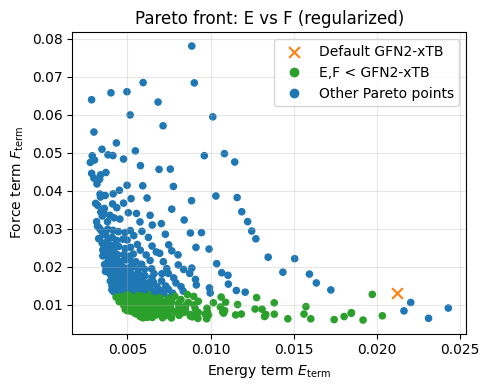

In [4]:
E_term = F_pareto[:, 0]
F_term = F_pareto[:, 1]
try:
    Reg_term = F_pareto[:, 2]
except:
    Reg_term = None
E0 = 0.0211937810
F0 = 0.0130317367

colors = np.where(np.where(F_pareto[:, 0] < E0, True, False) * np.where(F_pareto[:, 1] < F0, True, False) == True, 'tab:green', 'tab:blue')
green_proxy = Line2D([0], [0], marker='o', linestyle='', color='tab:green', label='E,F,Mu,Fdir < GFN2')
blue_proxy = Line2D([0], [0], marker='o', linestyle='', color='tab:blue', label='Other Pareto points')

plt.figure(figsize=(5, 4))
plt.scatter(E_term, F_term, s=20, c=colors, label="_nolegend_")
plt.scatter([E0], [F0], s=60, marker="x", c='tab:orange', label="Default GFN2-xTB")
plt.xlabel("Energy term $E_{\\text{term}}$")
plt.ylabel("Force term $F_{\\text{term}}$")
plt.title("Pareto front: E vs F (regularized)")
plt.grid(True, alpha=0.3)
ax = plt.gca()
handles, labels = ax.get_legend_handles_labels()
handles.extend([green_proxy, blue_proxy])
labels.extend(['E,F < GFN2-xTB', 'Other Pareto points'])
plt.legend(handles, labels)
plt.tight_layout()
plt.show()

In [5]:
F = np.asarray(F_pareto, dtype=float)
X = np.asarray(X_pareto, dtype=float)

E = F[:, 0]
Fterm = F[:, 1]
try:
    Reg = F[:, 2]
except:
    Reg = 0.0

# 1. Базовый фильтр: энергия не хуже default
mask = (E <= E0) & (Fterm <= F0) & ((E < E0) | (Fterm < F0))

# 2. Регуляризация как constraint.
# Если ты считаешь, что все Reg значения терпимые, оставь np.inf.
R_max = np.inf


mask = mask & (Reg <= R_max)

F_cand = F[mask]
X_cand = X[mask]
idx_cand = np.flatnonzero(mask)

if len(F_cand) == 0:
    raise ValueError("No candidates after E/Reg filtering.")

# 3. ASF только для E и F
weights = np.array([0.1, 0.9])  # E, F
weights = weights / weights.sum()

F_norm = F_cand[:, :2] / np.array([E0, F0])

ideal = np.min(F_norm, axis=0)

rho = 1e-6
delta = F_norm - ideal

asf_values = (
    np.max(weights * delta, axis=1)
    + rho * np.sum(weights * delta, axis=1)
)

j = np.argmin(asf_values)

asf_selected_idx = idx_cand[j]
asf_params = X_cand[j]
asf_objectives = F_cand[j]

print("asf_selected_idx:", asf_selected_idx)
print("E/F ratios:", asf_objectives[:2] / np.array([E0, F0]))
print("raw E/F values:", asf_objectives[:2])
try: 
    print("Reg value:", asf_objectives[2])
except:
    pass
print("asf_weights [E, F]:", weights)
print("asf_value:", asf_values[j])
print("asf_params:", asf_params)

asf_selected_idx: 249
E/F ratios: [0.46068387 0.48850726]
raw E/F values: [0.00976363 0.0063661 ]
Reg value: 0.13465449182309794
asf_weights [E, F]: [0.1 0.9]
asf_value: 0.025688817762625066
asf_params: [1.05311312 1.01475757 1.09455895 2.53002024 6.9280278  1.99412909]


In [ ]:
candidates_idx = []
for w in [0.99, 0.98, 0.96, 0.9, 0.88, 0.8, 0.6, 0.4, 0.3, 0.2, 0.1, 0.01]:
    weights = np.array([1-w, w])  # E, F
    weights = weights / weights.sum()
    print(f"\nASF selection with weights E:{weights[0]:.2f}, F:{weights[1]:.2f}")
    F_norm = F_cand[:, :2] / np.array([E0, F0])

    ideal = np.min(F_norm, axis=0)

    rho = 1e-6
    delta = F_norm - ideal

    asf_values = (
        np.max(weights * delta, axis=1)
        + rho * np.sum(weights * delta, axis=1)
    )

    j = np.argmin(asf_values)

    asf_selected_idx = idx_cand[j]
    asf_params = X_cand[j]
    asf_objectives = F_cand[j]

    print("asf_selected_idx:", asf_selected_idx)
    print("E/F ratios:", asf_objectives[:2] / np.array([E0, F0]))
    print("raw E/F values:", asf_objectives[:2])
    print("Reg value:", asf_objectives[2])
    print("asf_weights [E, F]:", weights)
    print("asf_value:", asf_values[j])
    print("asf_params:", asf_params)

    candidates_idx.append(asf_selected_idx)

print("\nFinal candidate indices from ASF selection:", candidates_idx)


ASF selection with weights E:0.01, F:0.99
asf_selected_idx: 252
E/F ratios: [0.90410357 0.46324608]
raw E/F values: [0.01916137 0.0060369 ]
Reg value: 0.19548564903400525
asf_weights [E, F]: [0.01 0.99]
asf_value: 0.007003080971480886
asf_params: [1.02275182 1.02443801 1.15387448 2.75883474 6.03896258 1.74045719]

ASF selection with weights E:0.02, F:0.98
asf_selected_idx: 34
E/F ratios: [0.82213982 0.47188526]
raw E/F values: [0.01742425 0.00614948]
Reg value: 0.15737219160781005
asf_weights [E, F]: [0.02 0.98]
asf_value: 0.012366893816340022
asf_params: [1.02761256 1.02522516 1.14387344 2.68990606 6.27200219 1.8082407 ]

ASF selection with weights E:0.04, F:0.96
asf_selected_idx: 287
E/F ratios: [0.75591073 0.48766553]
raw E/F values: [0.01602061 0.00635513]
Reg value: 0.09772870819407403
asf_weights [E, F]: [0.04 0.96]
asf_value: 0.02344270916854571
asf_params: [1.02497686 1.01336083 1.11720727 2.52905031 6.67906795 1.98921456]

ASF selection with weights E:0.10, F:0.90
asf_selecte

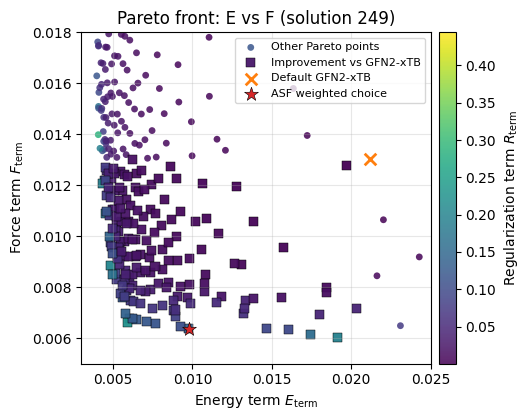

In [8]:
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
better_mask = (
    (E_term <= E0) &
    (F_term <= F0) &
    ((E_term < E0) | (F_term < F0))
)

F_better = F_pareto[better_mask]
X_better = X_pareto[better_mask]
improvement_mask = better_mask
other_mask = ~improvement_mask

# Color encodes regularization.
# Можно заменить "magma" на "viridis", "plasma", "cividis".
reg_cmap = "viridis"

reg_norm = Normalize(
    vmin=np.nanmin(Reg_term),
    vmax=np.nanmax(Reg_term),
)

def plot_pareto_with_reg_heatmap(
    x, y,
    x0, y0,
    asf_x, asf_y,
    xlabel, ylabel, title,
):
    fig, ax = plt.subplots(figsize=(5.4, 4.3))

    # Other Pareto points: circles
    sc = ax.scatter(
        x[other_mask],
        y[other_mask],
        c=Reg_term[other_mask],
        cmap=reg_cmap,
        norm=reg_norm,
        s=24,
        marker="o",
        alpha=0.85,
        edgecolors="none",
        label="Other Pareto points",
    )

    # Improved solutions: squares
    ax.scatter(
        x[improvement_mask],
        y[improvement_mask],
        c=Reg_term[improvement_mask],
        cmap=reg_cmap,
        norm=reg_norm,
        s=42,
        marker="s",
        alpha=0.95,
        edgecolors="black",
        linewidths=0.35,
        label=r"Improvement vs GFN2-xTB",
    )

    # Reference / selected points
    ax.scatter(
        [x0], [y0],
        s=70,
        marker="x",
        c="tab:orange",
        linewidths=2.0,
        label="Default GFN2-xTB",
        zorder=5,
    )

    ax.scatter(
        [asf_x], [asf_y],
        s=110,
        marker="*",
        c="tab:red",
        edgecolors="black",
        linewidths=0.4,
        label="ASF weighted choice",
        zorder=7,
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xlim((0.003, 0.025))
    ax.set_ylim((0.005, 0.018))

    ax.grid(True, alpha=0.3)

    cbar = fig.colorbar(sc, ax=ax, pad=0.02)
    cbar.set_label(r"Regularization term $R_{\mathrm{term}}$")

    ax.legend(fontsize=8, frameon=True)
    fig.tight_layout()
    plt.savefig(os.path.join(PROJECT_ROOT, 'optimization/analyze_pareto/pareto_EFQ.png'), dpi=300)
    plt.show()


# ----------------------- E vs F ----------------------- #
idx = 3
plot_pareto_with_reg_heatmap(
    x=E_term,
    y=F_term,
    x0=E0,
    y0=F0,
    asf_x=F_pareto[candidates_idx[idx]][0],
    asf_y=F_pareto[candidates_idx[idx]][1],
    xlabel=r"Energy term $E_{\mathrm{term}}$",
    ylabel=r"Force term $F_{\mathrm{term}}$",
    title=f"Pareto front: E vs F (solution {candidates_idx[idx]})",
)

In [ ]:
base_param_file = os.path.join(PROJECT_ROOT, 'gfn2-xtb.toml')
def save_param_toml(vector, out_dir, name):
    param_dict = vector_to_param_changes(vector, structure)
    path_to_save = ensure_param_file(param_dict, param_file=str(base_param_file), DIR=out_dir)
    #rename the file
    os.rename(path_to_save, os.path.join(out_dir, f"{name}.toml"))

for idx in [asf_selected_idx]:
    save_param_toml(X_pareto[idx], os.path.join(PROJECT_ROOT, 'parameter_files'), f'nsga3_EF_water_full_reg_6_params_{idx}')